## Which position does the race winner begin the last restart at?

#### Step 1: Get the data

Create a function that retrieves race telemtry data to grab the race winner and his position at the last restart and return that position

In [2]:
from pynascar import Race

#create function to get the winner's position at last restart

def race_data(race_id=5596):
    # start with one race - daytona 500 2026
    try:
        race = Race(year=2026, series_id=1, race_id=race_id, reload=True)
    except:
        return
    # lap of last caution
    last_caution_lap = race.results.cautions.tail(1)['end_lap'].iloc[0]

    # driver who won
    winner = race.results.results[race.results.results['finishing_position'] == 1]["driver_name"].iloc[0]

    # get position data
    df_laps = race.telemetry.lap_times

    # filter for that specific lap
    lap_data = df_laps[df_laps['Lap'] == last_caution_lap]

    winner_position = lap_data[lap_data['driver_name'] == winner]['position'].iloc[0]

    return winner_position

Loop through all 2026 cup series races. Adjust race_ids as needed, 5596 is Daytona 500 for 2026

In [3]:
# loop through all races in 2026 season
position_list = []
for i in range(5596, 5628):
    position_list.append(race_data(i))

Fetching Data for 2026-1-5596
Fetching Data for 2026-1-5597
Fetching Data for 2026-1-5598
Fetching Data for 2026-1-5599
Fetching Data for 2026-1-5600
Fetching Data for 2026-1-5601
Fetching Data for 2026-1-5602
Fetching Data for 2026-1-5603
Fetching Data for 2026-1-5604
Fetching Data for 2026-1-5605
Fetching Data for 2026-1-5606
Fetching Data for 2026-1-5607
Fetching Data for 2026-1-5608
Failed to fetch data for https://cf.nascar.com/cacher/2026/1/5608/weekend-feed.json. Error: 403 Client Error: Forbidden for url: https://cf.nascar.com/cacher/2026/1/5608/weekend-feed.json
Failed to fetch race data for: 2026-1-5608
Failed to fetch data for https://cf.nascar.com/cacher/2026/1/5608/lap-times.json. Error: 403 Client Error: Forbidden for url: https://cf.nascar.com/cacher/2026/1/5608/lap-times.json
Failed to fetch data for https://cf.nascar.com/cacher/2026/1/5608/live-pit-data.json. Error: 403 Client Error: Forbidden for url: https://cf.nascar.com/cacher/2026/1/5608/live-pit-data.json
Failed 

#### Step 2: Clean the data

Remove Nones from the list for races with unavailable data

In [ ]:
clean_position_list = [item for item in position_list if item is not None]
print(clean_position_list)

[np.int64(2), np.int64(3), np.int64(1), np.int64(2), np.int64(2), np.int64(2), np.int64(10), np.int64(1), np.int64(1), np.int64(2), np.int64(2), np.int64(1), np.int64(1), np.int64(3), np.int64(3), np.int64(4), np.int64(2), np.int64(2), np.int64(3), np.int64(1), np.int64(1), np.int64(1), np.int64(5), np.int64(1), np.int64(2), np.int64(1), np.int64(5), np.int64(1), np.int64(5), np.int64(1)]


#### Step 3: Visualize the data

Use matplotlib to plot the data. Plot the values in the list on the x-axis and their frequency on the y-axis

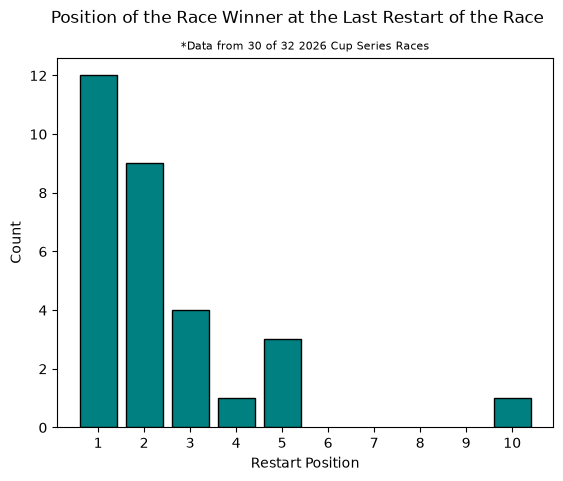

In [ ]:
import matplotlib.pyplot as plt
from collections import Counter

counts = Counter(clean_position_list)

categories = list(counts.keys())
frequencies = list(counts.values())

plt.bar(categories, frequencies, color='teal', edgecolor='black')

full_range = range(min(clean_position_list), max(clean_position_list) + 1)

plt.xticks(full_range)
plt.xlabel('Restart Position')
plt.ylabel('Count')
plt.suptitle('Position of the Race Winner at the Last Restart of the Race', fontsize=12)
plt.title('*Data from 30 of 32 2026 Cup Series Races', fontsize=8)
plt.show()

Bonus: additional conclusions

In [8]:
print("The average position of a race's winner at the last restart of the race for the 2026 season:", round(sum(clean_position_list) / len(clean_position_list),2))
print("The worst restart position of a race's winner for the 2026 season:", max(clean_position_list))
print(clean_position_list.count(1), "times the race's winner restarted the last restart in first for the 2026 season")
print("*Note: Data available for", len(clean_position_list), "out of", len(position_list), "races of the 2026 season")

The average position of a race's winner at the last restart of the race for the 2026 season: 2.37
The worst restart position of a race's winner for the 2026 season: 10
12 times the race's winner restarted the last restart in first for the 2026 season
*Note: Data available for 30 out of 32 races of the 2026 season
